# 04b · Hedonic model: validation, tuning, ablation, intervals and backtest
**Owner:** Pricing & Availability Lead · **Needs:** steps 1b–6; `lightgbm`, `shap` · Production code: `src/homefit/hedonic.py`

Notebook 04 showed the model is accurate on unseen blocks. This notebook stress-tests it:

| § | Question | Method |
|---|---|---|
| 1 | Does accuracy hold for unseen blocks, a later period and unseen towns? | Three validation designs vs the linear time-dummy benchmark |
| 2 | Are the hyperparameters reasonable? | Random search on a time split |
| 3 | Which feature groups earn their place? Do the monotone constraints cost accuracy? | Ablation; neighbourhood premium; latitude/longitude |
| 4 | Is anything left in the errors? | Residuals by year, flat type, town; Moran's I on residuals |
| 5 | How wide should a price range be? | Split-conformal prediction intervals and their coverage |
| 6 | Which features interact? | SHAP interaction values |
| 7 | Does the profile pricing hold up over time? | Rolling backtest at 7 dates, 2019–2025 |
| 8 | Does our price index agree with the official one? | Comparison with HDB's Resale Price Index |

In [1]:
import sys, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import config as C
from homefit import common as K, hedonic as H, profiles as PR
from sklearn.model_selection import GroupKFold
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
BLUE, GREY, ORANGE, GREEN = "#2a78d6", "#9a9a95", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a9a95", "lines.linewidth": 1.8, "legend.frameon": False, "font.size": 10})
AS_OF = K.latest_complete_month()
d = H.training_frame(AS_OF).reset_index(drop=True)
print(f"As of {AS_OF}: {len(d):,} sales for training · {len(H.FEATURES)} features")

def train(tr, feats=H.FEATURES, params=None, rounds=2000, mono=True, valid=None, es=100):
    Xt = tr[feats].copy(); cats = {}
    for c in [f for f in feats if f in H.CAT]:
        Xt[c] = pd.Categorical(Xt[c]); cats[c] = Xt[c].cat.categories
    p = dict(H.PARAMS, **(params or {})); p["monotone_constraints"] = [H.MONOTONE.get(c, 0) if mono else 0 for c in feats]
    y = np.log(tr["resale_price"].to_numpy())
    if valid is not None:
        Xv = valid[feats].copy()
        for c, cat in cats.items(): Xv[c] = pd.Categorical(Xv[c], categories=cat)
        m = lgb.train(p, lgb.Dataset(Xt, y), num_boost_round=rounds, valid_sets=[lgb.Dataset(Xv, np.log(valid["resale_price"].to_numpy()))],
                      callbacks=[lgb.early_stopping(es, verbose=False)])
    else:
        m = lgb.train(p, lgb.Dataset(Xt, y), num_boost_round=rounds)
    m.feats_, m.cats_ = feats, cats
    return m

def predict(m, df):
    Xd = df[m.feats_].copy()
    for c, cat in m.cats_.items(): Xd[c] = pd.Categorical(Xd[c], categories=cat)
    return np.exp(m.predict(Xd, num_iteration=m.best_iteration if m.best_iteration > 0 else None))

def scores(y, p):
    ape = np.abs(p / y - 1); r = np.log(y) - np.log(p)
    return {"MAPE": ape.mean(), "median APE": np.median(ape), "within 10%": (ape <= 0.10).mean(),
            "R2 (log)": 1 - np.var(r) / np.var(np.log(y)), "RMSE (log)": np.sqrt(np.mean(r ** 2))}

rng = np.random.default_rng(0)
blocks = d["address"].unique()
test_blocks = set(rng.choice(blocks, int(len(blocks) * 0.2), replace=False))      # same split as hedonic.evaluate
te_blk = d["address"].isin(test_blocks).to_numpy()

As of 2026-09: 241,273 sales for training · 18 features


## 1 · Three validation designs
- **Unseen blocks** (production test): 20% of blocks held out, all their sales scored.
- **Later period**: train on sales up to Sep 2024, score Oct 2024 – Sep 2025 (a forecast-free test of how fast the model ages: month is set to the sale month, which the model never saw, so it uses its last learned level).
- **Unseen towns**: 5-fold cross-validation by groups of towns; every town is scored once by a model that never saw it. Run twice: with the town feature (an unseen town gets no town effect) and without it, using coordinates instead, which is how a brand-new town such as Tengah would have to be priced.

Production settings throughout (learning rate 0.05, 2,000 trees). Benchmark: the linear time-dummy hedonic regression.

In [2]:
t1 = time.time(); results, store = [], {}
m_blk = train(d[~te_blk]); p_blk = predict(m_blk, d[te_blk]); store["blocks"] = (d[te_blk].copy(), p_blk)
results.append({"design": "Unseen blocks (20%)", "model": "LightGBM", **scores(d.loc[te_blk, "resale_price"].to_numpy(), p_blk)})
results.append({"design": "Unseen blocks (20%)", "model": "Linear time-dummy", **scores(d.loc[te_blk, "resale_price"].to_numpy(), H._linear_baseline(d[~te_blk], d[te_blk]))})
print(f"unseen blocks done {time.time() - t1:.0f}s")

tr_t, te_t = d[d["month"] <= "2024-09"], d[(d["month"] > "2024-09") & (d["month"] <= "2025-09")]
m_oot = train(tr_t); p_oot = predict(m_oot, te_t); store["later"] = (te_t.copy(), p_oot)
results.append({"design": "Later period (Oct 2024 – Sep 2025)", "model": "LightGBM", **scores(te_t["resale_price"].to_numpy(), p_oot)})
lin_oot = H._linear_baseline(tr_t, te_t.assign(month=tr_t["month"].max()))          # unseen months -> last known month effect
results.append({"design": "Later period (Oct 2024 – Sep 2025)", "model": "Linear time-dummy", **scores(te_t["resale_price"].to_numpy(), lin_oot)})
print(f"later period done {time.time() - t1:.0f}s")

pt, pl = np.zeros(len(d)), np.zeros(len(d)); fold_rows = []
for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(d, groups=d["town"])):
    m = train(d.iloc[a]); pt[b] = predict(m, d.iloc[b]); pl[b] = H._linear_baseline(d.iloc[a], d.iloc[b])
    fold_rows.append({"fold": k + 1, "towns": ", ".join(sorted(d.iloc[b]["town"].unique()))[:80] + "…", **scores(d.iloc[b]["resale_price"].to_numpy(), pt[b])})
    print(f"town fold {k + 1} done {time.time() - t1:.0f}s")
results.append({"design": "Unseen towns (5 folds)", "model": "LightGBM", **scores(d["resale_price"].to_numpy(), pt)})
NOTOWN = [f for f in H.FEATURES if f != "town"] + ["lat", "lon"]
pn = np.zeros(len(d))
for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(d, groups=d["town"])):
    pn[b] = predict(train(d.iloc[a], feats=NOTOWN), d.iloc[b])
results.append({"design": "Unseen towns (5 folds)", "model": "LightGBM without town, with coordinates", **scores(d["resale_price"].to_numpy(), pn)})
print(f"unseen towns without the town feature done {time.time() - t1:.0f}s")
results.append({"design": "Unseen towns (5 folds)", "model": "Linear time-dummy", **scores(d["resale_price"].to_numpy(), pl)})
val = pd.DataFrame(results).set_index(["design", "model"])
print(val.round(4).to_string())
print(pd.DataFrame(fold_rows).set_index("fold").round(4).to_string())
by_town = pd.DataFrame({"town": d["town"], "ape": np.abs(pn / d["resale_price"] - 1)}).groupby("town")["ape"].mean().sort_values()
print("Unseen-town MAPE without the town feature, best 3:", by_town.head(3).round(3).to_dict(), "· worst 3:", by_town.tail(3).round(3).to_dict())

unseen blocks done 657s


later period done 684s


town fold 1 done 714s


town fold 2 done 742s


town fold 3 done 771s


town fold 4 done 811s


town fold 5 done 1444s


unseen towns without the town feature done 1567s
                                                                              MAPE  median APE  within 10%  R2 (log)  RMSE (log)
design                             model                                                                                        
Unseen blocks (20%)                LightGBM                                 0.0391      0.0300      0.9407    0.9765      0.0525
                                   Linear time-dummy                        0.0663      0.0537      0.7802    0.9371      0.0858
Later period (Oct 2024 – Sep 2025) LightGBM                                 0.0437      0.0374      0.9384    0.9759      0.0570
                                   Linear time-dummy                        0.0694      0.0590      0.7605    0.9234      0.0902
Unseen towns (5 folds)             LightGBM                                 0.2213      0.1949      0.2514    0.7657      0.2308
                                   LightGBM with

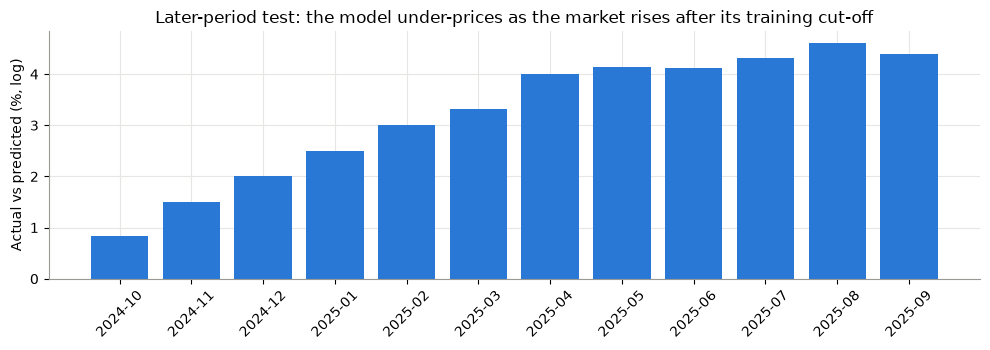

           MAPE    bias
month                  
2024-10  0.0321  0.0084
2024-11  0.0343  0.0150
2024-12  0.0347  0.0201
2025-01  0.0383  0.0250
2025-02  0.0420  0.0301
2025-03  0.0431  0.0332
2025-04  0.0473  0.0400
2025-05  0.0481  0.0415
2025-06  0.0489  0.0413
2025-07  0.0498  0.0431
2025-08  0.0519  0.0461
2025-09  0.0509  0.0440


In [3]:
te_t2 = te_t.assign(ape=np.abs(p_oot / te_t["resale_price"] - 1), bias=np.log(te_t["resale_price"] / p_oot))
mm = te_t2.groupby("month").agg(MAPE=("ape", "mean"), bias=("bias", "mean"))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(mm.index, mm["bias"] * 100, color=[BLUE if v > 0 else GREY for v in mm["bias"]])
ax.set(ylabel="Actual vs predicted (%, log)", title="Later-period test: the model under-prices as the market rises after its training cut-off")
ax.tick_params(axis="x", rotation=45); plt.tight_layout(); plt.show()
print(mm.round(4).to_string())

**Finding:** The model generalises well to new blocks and new periods. Generalising to new towns works only once it stops relying on the town label:

| Validation design | LightGBM MAPE | Linear benchmark MAPE |
|---|---|---|
| Unseen blocks | 3.9% (94% within 10%) | 6.6% |
| Later period (Oct 2024 – Sep 2025) | 4.4% | 6.9% |
| Unseen towns, with the town feature | 22.1% | 23.6% |
| Unseen towns, without town, with coordinates | **8.0%** (71% within 10%, R² 0.92) | — |

- **Later period:** error grows month by month (3.2% to 5.1%) and the bias reaches +4.4% after a year. The model holds its last learned market level while prices keep rising, which is exactly the gap the forecasting layer fills, and why prices must be refreshed monthly.
- **Unseen towns:** with the town feature, an unseen town gets no town effect, so the model fails (22%). Without the label it prices towns it never saw at 8.0%, best in Punggol, Pasir Ris and Sengkang (5–6%) and worst in Bukit Timah (22%), a town unlike any other. That is the variant to use for a brand-new town such as Tengah. With the town feature, existing towns are priced at 3.9%.

## 2 · Hyperparameter search
Random search over tree size and regularisation on a time split (train to Sep 2023, validate Oct 2023 – Sep 2024), learning rate
0.1 with early stopping to keep it fast. The production setting is included as a candidate.

In [4]:
tr_s, va_s = d[d["month"] <= "2023-09"], d[(d["month"] > "2023-09") & (d["month"] <= "2024-09")]
space = dict(num_leaves=[31, 63, 127, 255], min_child_samples=[20, 40, 100, 200], colsample_bytree=[0.6, 0.8, 1.0], reg_lambda=[0, 1, 5, 20])
r = np.random.default_rng(3)
cands = [dict(num_leaves=63, min_child_samples=40, colsample_bytree=0.8, reg_lambda=1.0)] + \
        [{k: v[r.integers(len(v))] for k, v in space.items()} for _ in range(8)]
rows = []; t1 = time.time()
for i, c in enumerate(cands):
    m = train(tr_s, params=dict(c, learning_rate=0.1), rounds=3000, valid=va_s)
    rows.append({"candidate": "production" if i == 0 else f"random {i}", **c, "trees": m.best_iteration, **scores(va_s["resale_price"].to_numpy(), predict(m, va_s))})
tune = pd.DataFrame(rows).set_index("candidate").sort_values("MAPE")
print(f"{len(cands)} candidates in {time.time() - t1:.0f}s"); print(tune.round(4).to_string())

9 candidates in 83s
            num_leaves  min_child_samples  colsample_bytree  reg_lambda  trees    MAPE  median APE  within 10%  R2 (log)  RMSE (log)
candidate                                                                                                                           
random 6            63                 40               1.0         5.0   1024  0.0512      0.0435      0.8870    0.9683      0.0669
random 5           127                100               0.6         0.0    770  0.0513      0.0440      0.8866    0.9687      0.0670
random 7            63                 40               0.8         5.0    962  0.0516      0.0441      0.8850    0.9683      0.0674
production          63                 40               0.8         1.0    895  0.0516      0.0440      0.8832    0.9680      0.0675
random 4           127                 40               0.6         0.0    563  0.0518      0.0442      0.8824    0.9680      0.0676
random 1           255                 20        

**Finding:** The production settings are within 0.04 percentage points of the best of 9 candidates (validation MAPE 5.16% against 5.12%). Tree size and regularisation barely matter in the range tried, so the model is not over-tuned, and re-tuning would not change any conclusion.

## 3 · Ablation: which features earn their place?
Each variant is trained on the same 80% of blocks and scored on the same 20% (learning rate 0.1, 1,000 trees, the same for every variant).

The **neighbourhood premium** is new: for each block, the average location premium of *other* blocks within 500 m, computed from the
training blocks only (no leakage), suggested by the spatial clustering in notebook 05.

In [5]:
tr_b = d[~te_blk]
yv = np.log(tr_b["price_psm"]); yv = yv - yv.groupby([tr_b["month"], tr_b["flat_type"]]).transform("mean")
Xm = pd.concat([tr_b[["remaining_lease_yrs", "storey_mid"]].assign(l2=tr_b["remaining_lease_yrs"] ** 2 / 100),
                pd.get_dummies(tr_b["flat_model_group"], drop_first=True, dtype=float)], axis=1)
Xm = (Xm - Xm.mean()).to_numpy(float); beta, *_ = np.linalg.lstsq(Xm, yv.to_numpy(), rcond=None)
prem_blk = pd.Series(yv.to_numpy() - Xm @ beta, index=tr_b.index).groupby(tr_b["address"]).mean()
bxy = K.blocks().set_index("address")[["lat", "lon"]].dropna()
xy = lambda a: np.c_[(bxy.loc[a, "lon"] - 103.8) * 111_320 * np.cos(np.radians(1.35)), (bxy.loc[a, "lat"] - 1.35) * 110_574]
src = prem_blk.index.intersection(bxy.index); tree = cKDTree(xy(src)); vals = prem_blk.loc[src].to_numpy()
allb = d["address"].unique(); allb = allb[np.isin(allb, bxy.index)]
nbr = {}
for a, nb_ in zip(allb, tree.query_ball_point(xy(allb), r=500)):
    v = [vals[j] for j in nb_ if src[j] != a]
    nbr[a] = np.mean(v) if v else np.nan
d["nbr_prem_500m"] = d["address"].map(nbr)
print(f"Neighbourhood premium available for {d['nbr_prem_500m'].notna().mean():.1%} of sales")

AMEN = ["dist_hawker_m", "dist_park_m", "dist_supermarket_m", "dist_polyclinic_m", "dist_primary_m", "n_primary_1km", "n_preschool_500m", "n_chas_500m", "n_supermarket_500m"]
base = list(H.FEATURES)
variants = [("Production feature set", base, True), ("No monotone constraints", base, False),
            ("Without amenities", [f for f in base if f not in AMEN], True), ("Without MRT distance", [f for f in base if f != "dist_mrt_m"], True),
            ("Town only (no MRT, no amenities)", [f for f in base if f not in AMEN + ["dist_mrt_m"]], True),
            ("+ latitude and longitude", base + ["lat", "lon"], True), ("+ neighbourhood premium (500 m)", base + ["nbr_prem_500m"], True)]
rows = []; t1 = time.time(); abl_models = {}
for name, feats, mono in variants:
    m = train(d[~te_blk], feats=feats, params=dict(learning_rate=0.1), rounds=1000, mono=mono)
    p = predict(m, d[te_blk]); abl_models[name] = (m, p)
    rows.append({"variant": name, "features": len(feats), **scores(d.loc[te_blk, "resale_price"].to_numpy(), p)})
abl = pd.DataFrame(rows).set_index("variant")
abl["MAPE change (pp)"] = (abl["MAPE"] - abl.loc["Production feature set", "MAPE"]) * 100
print(f"{len(variants)} variants in {time.time() - t1:.0f}s"); print(abl.round(4).to_string())
mono_m = abl_models["No monotone constraints"][0]
grid = d[te_blk].sample(2000, random_state=0)
viol = {}
for f in ["floor_area_sqm", "remaining_lease_yrs", "storey_mid"]:
    lo, hi = grid.copy(), grid.copy(); hi[f] = hi[f] + (5 if f != "storey_mid" else 3)
    viol[f] = (predict(mono_m, hi) < predict(mono_m, lo)).mean()
print("Unconstrained model: share of flats whose predicted price FALLS when this improves (+5 sqm / +5 years / +3 floors):", {k: f"{v:.1%}" for k, v in viol.items()})

Neighbourhood premium available for 100.0% of sales


7 variants in 78s
                                  features    MAPE  median APE  within 10%  R2 (log)  RMSE (log)  MAPE change (pp)
variant                                                                                                           
Production feature set                  18  0.0396      0.0305      0.9390    0.9760      0.0531            0.0000
No monotone constraints                 18  0.0387      0.0299      0.9435    0.9769      0.0520           -0.0901
Without amenities                        9  0.0428      0.0327      0.9200    0.9716      0.0577            0.3181
Without MRT distance                    17  0.0402      0.0311      0.9356    0.9755      0.0535            0.0609
Town only (no MRT, no amenities)         8  0.0493      0.0373      0.8827    0.9623      0.0665            0.9650
+ latitude and longitude                20  0.0391      0.0303      0.9408    0.9766      0.0524           -0.0491
+ neighbourhood premium (500 m)         19  0.0395      0.0303

Unconstrained model: share of flats whose predicted price FALLS when this improves (+5 sqm / +5 years / +3 floors): {'floor_area_sqm': '3.8%', 'remaining_lease_yrs': '27.6%', 'storey_mid': '2.8%'}


**Finding:** Each feature group's contribution to MAPE on unseen blocks, against the production set (3.96% in this faster set-up):

| Variant | Change in MAPE | Reading |
|---|---|---|
| Without amenities | +0.32 pp | Amenities earn their place |
| Town only (no MRT, no amenities) | +0.97 pp | Location below town level matters |
| Without MRT distance | +0.06 pp | Small *marginal* gain: MRT overlaps with town and amenity features, though its SHAP effect is large |
| + latitude and longitude | −0.05 pp | Negligible; left out to keep MRT and amenity effects interpretable |
| + neighbourhood premium (500 m) | −0.02 pp | Negligible: the model already captures the spatial clustering (see §4) |
| No monotone constraints | −0.09 pp | But see below |

**Monotone constraints are justified.** Without them, raising a flat's remaining lease by 5 years *lowers* its predicted price for 27.6% of flats; for floor area and storey the figures are 3.8% and 2.8%. Giving up 0.09 pp of accuracy for prices that always rise with size, lease and floor is the right trade for a tool that compares options.

## 4 · Residual diagnostics (unseen-block test, production model)

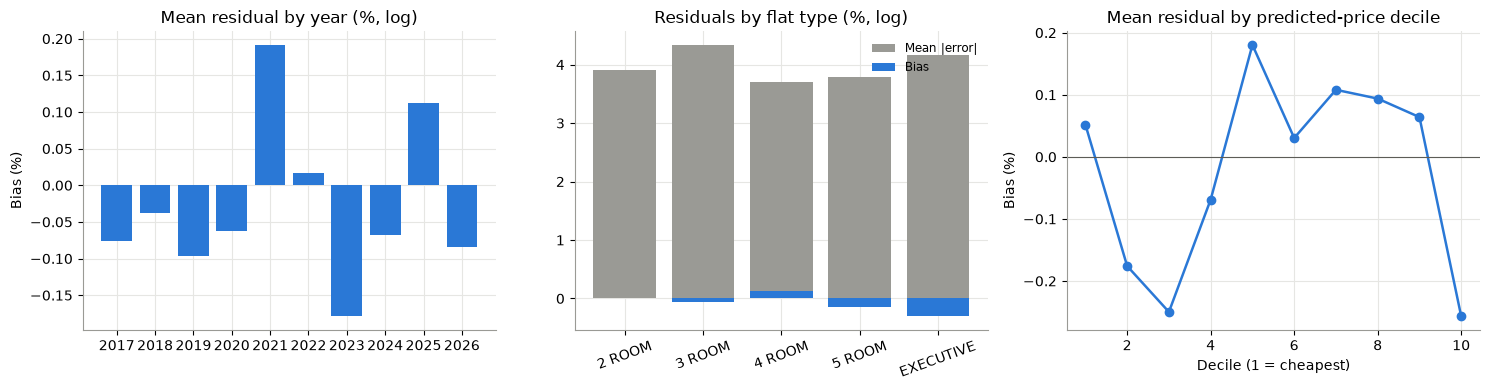

Bias by year (%): {'2017': -0.08, '2018': -0.04, '2019': -0.1, '2020': -0.06, '2021': 0.19, '2022': 0.02, '2023': -0.18, '2024': -0.07, '2025': 0.11, '2026': -0.08}
Bias by price decile (%): [0.05, -0.18, -0.25, -0.07, 0.18, 0.03, 0.11, 0.09, 0.06, -0.26]
Moran's I of block-mean residuals (unseen blocks, 8 nearest): 0.066 (p = 0.005) vs 0.861 for the raw location premium (notebook 05)
Worst towns (unseen blocks), MAPE: {'TOA PAYOH': 0.051, 'MARINE PARADE': 0.051, 'BUKIT MERAH': 0.055, 'QUEENSTOWN': 0.055, 'GEYLANG': 0.056}


In [6]:
tb, pb = store["blocks"]; tb = tb.assign(pred=pb, res=np.log(tb["resale_price"] / pb), ape=np.abs(pb / tb["resale_price"] - 1))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
yr = tb.groupby(tb["month"].str[:4])["res"].agg(["mean", "std"])
ax[0].bar(yr.index, yr["mean"] * 100, color=BLUE); ax[0].set(title="Mean residual by year (%, log)", ylabel="Bias (%)")
ft = tb.groupby("flat_type")["res"].agg(["mean", lambda s: np.mean(np.abs(s))]).reindex(K.TYPES)
ax[1].bar(ft.index, ft.iloc[:, 1] * 100, color=GREY, label="Mean |error|"); ax[1].bar(ft.index, ft.iloc[:, 0] * 100, color=BLUE, label="Bias")
ax[1].set(title="Residuals by flat type (%, log)"); ax[1].legend(fontsize=8.5); ax[1].tick_params(axis="x", rotation=20)
q = pd.qcut(tb["pred"], 10); dec = tb.groupby(q)["res"].mean()
ax[2].plot(range(1, 11), dec.values * 100, marker="o", color=BLUE); ax[2].axhline(0, color="#5c5c57", lw=0.8)
ax[2].set(title="Mean residual by predicted-price decile", xlabel="Decile (1 = cheapest)", ylabel="Bias (%)")
plt.tight_layout(); plt.show()
print("Bias by year (%):", (yr["mean"] * 100).round(2).to_dict())
print("Bias by price decile (%):", (dec.values * 100).round(2).tolist())

rb = tb.groupby("address").agg(res=("res", "mean"), n=("res", "size")).join(K.blocks().set_index("address")[["lat", "lon"]]).query("n >= 5").dropna()
pxy = np.c_[(rb["lon"] - 103.8) * 111_320 * np.cos(np.radians(1.35)), (rb["lat"] - 1.35) * 110_574]
_, nb8 = cKDTree(pxy).query(pxy, k=9); nb8 = nb8[:, 1:]
def moran(v, nbr, perms=199):
    z = v - v.mean(); I = (z * z[nbr].mean(1)).sum() / (z ** 2).sum()
    g = np.random.default_rng(0); null = [(zp * zp[nbr].mean(1)).sum() / (zp ** 2).sum() for zp in (g.permutation(z) for _ in range(perms))]
    return I, (1 + sum(n >= I for n in null)) / (perms + 1)
I, pv = moran(rb["res"].to_numpy(), nb8)
print(f"Moran's I of block-mean residuals (unseen blocks, 8 nearest): {I:.3f} (p = {pv:.3f}) vs 0.861 for the raw location premium (notebook 05)")
print("Worst towns (unseen blocks), MAPE:", tb.groupby("town")["ape"].mean().sort_values().tail(5).round(3).to_dict())

**Finding:** The residuals are unbiased in every dimension checked:

- by year, within ±0.2%
- by flat type, within ±0.3%
- by price decile, within ±0.3%, so there is no systematic over-pricing of cheap flats or under-pricing of dear ones

Moran's I of block-mean residuals is 0.066, small though significant (p = 0.005), against 0.861 for the raw location premium in notebook 05. The model has absorbed almost all of the spatial structure, which is why the neighbourhood-premium feature added nothing. The largest errors remain in older central towns (Geylang, Queenstown, Bukit Merah: 5.5%), where renovation and condition are unobserved.

## 5 · Prediction intervals: split conformal
The unseen-block test set is split by block into a calibration half and an evaluation half. The interval half-width is the
calibration half's (1 − α) quantile of |log error|, which guarantees coverage when new flats resemble the calibration flats.
**Mondrian** conformal does the same per flat type. Coverage is then checked on the evaluation half and on the later-period test (a harder case: time shift).

In [7]:
blk_te = np.array(sorted(test_blocks)); g = np.random.default_rng(5); cal_b = set(g.choice(blk_te, len(blk_te) // 2, replace=False))
cal = tb[tb["address"].isin(cal_b)]; ev = tb[~tb["address"].isin(cal_b)]
lt, lp = store["later"]; lt = lt.assign(res=np.log(lt["resale_price"] / lp))
rows = []
for lvl in [0.8, 0.9]:
    n = len(cal); q = np.quantile(np.abs(cal["res"]), min(1, np.ceil((n + 1) * lvl) / n))
    qt = cal.groupby("flat_type")["res"].apply(lambda s: np.quantile(np.abs(s), min(1, np.ceil((len(s) + 1) * lvl) / len(s))))
    rows.append({"target": f"{lvl:.0%}", "method": "Global", "half-width (±%)": (np.exp(q) - 1) * 100,
                 "coverage, unseen blocks": (np.abs(ev["res"]) <= q).mean(), "coverage, later period": (np.abs(lt["res"]) <= q).mean()})
    rows.append({"target": f"{lvl:.0%}", "method": "Mondrian by flat type", "half-width (±%)": ((np.exp(qt) - 1) * 100).round(1).to_dict(),
                 "coverage, unseen blocks": (np.abs(ev["res"]) <= ev["flat_type"].map(qt)).mean(), "coverage, later period": (np.abs(lt["res"]) <= lt["flat_type"].map(qt)).mean()})
    sd = np.std(cal["res"]); z = {0.8: 1.2816, 0.9: 1.6449}[lvl]
    rows.append({"target": f"{lvl:.0%}", "method": "Normal ±z·σ (naive)", "half-width (±%)": (np.exp(z * sd) - 1) * 100,
                 "coverage, unseen blocks": (np.abs(ev["res"]) <= z * sd).mean(), "coverage, later period": (np.abs(lt["res"]) <= z * sd).mean()})
ci = pd.DataFrame(rows); print(ci.to_string(index=False))
by = ev.assign(cov=np.abs(ev["res"]) <= np.quantile(np.abs(cal["res"]), 0.8)).groupby("flat_type")["cov"].mean().reindex(K.TYPES)
print("Global 80% interval, coverage by flat type (evaluation half):", by.round(3).to_dict())

target                method                                                                half-width (±%)  coverage, unseen blocks  coverage, later period
   80%                Global                                                                       6.416628                 0.810972                0.739335
   80% Mondrian by flat type {'2 ROOM': 6.7, '3 ROOM': 7.1, '4 ROOM': 6.1, '5 ROOM': 6.2, 'EXECUTIVE': 6.9}                 0.810720                0.741052
   80%   Normal ±z·σ (naive)                                                                       7.052325                 0.843527                0.785278
   90%                Global                                                                       8.850329                 0.908216                0.875944
   90% Mondrian by flat type {'2 ROOM': 8.9, '3 ROOM': 9.8, '4 ROOM': 8.4, '5 ROOM': 8.5, 'EXECUTIVE': 9.0}                 0.907712                0.875334
   90%   Normal ±z·σ (naive)                              

**Finding:** Split-conformal intervals deliver their stated coverage on new blocks:

| Interval | Half-width | Coverage, unseen blocks | Coverage, later period |
|---|---|---|---|
| 80% | ±6.4% | 81.1% | 73.9% |
| 90% | ±8.9% | 90.8% | 87.6% |

- **Over time:** coverage falls in the later period because prices drift after the training cut-off (§1). Intervals should be recalibrated whenever the model is refreshed.
- **By flat type:** the global interval over-covers 2-room (84%) and under-covers 3-room and Executive (77%). Mondrian (per-flat-type) widths of 6.1–7.1% correct this.
- **The naive normal interval** (±z·σ) over-covers at 80% and under-covers at 90%: the errors are heavier-tailed than normal. Conformal makes no such assumption.

A ±6.4% band (80%) is the honest uncertainty for a single flat's price, and is a better basis for `price_today_se` than the RMSE.

## 6 · SHAP interactions
SHAP interaction values split each prediction into main effects and pairwise interactions (500 recent sales, production model).

interaction values in 366s
Largest main effects (mean |SHAP|, log price): [('t', np.float64(0.2213)), ('floor_area_sqm', np.float64(0.1187)), ('town', np.float64(0.1018)), ('flat_type', np.float64(0.0801)), ('remaining_lease_yrs', np.float64(0.0767)), ('dist_mrt_m', np.float64(0.0344))]
Largest interactions (mean |SHAP|, log price):
  floor_area_sqm × town: 0.0197
  floor_area_sqm × flat_type: 0.0181
  remaining_lease_yrs × town: 0.0178
  t × town: 0.0139
  remaining_lease_yrs × t: 0.0129
  t × flat_type: 0.0118
  floor_area_sqm × t: 0.0092
  flat_type × town: 0.0086


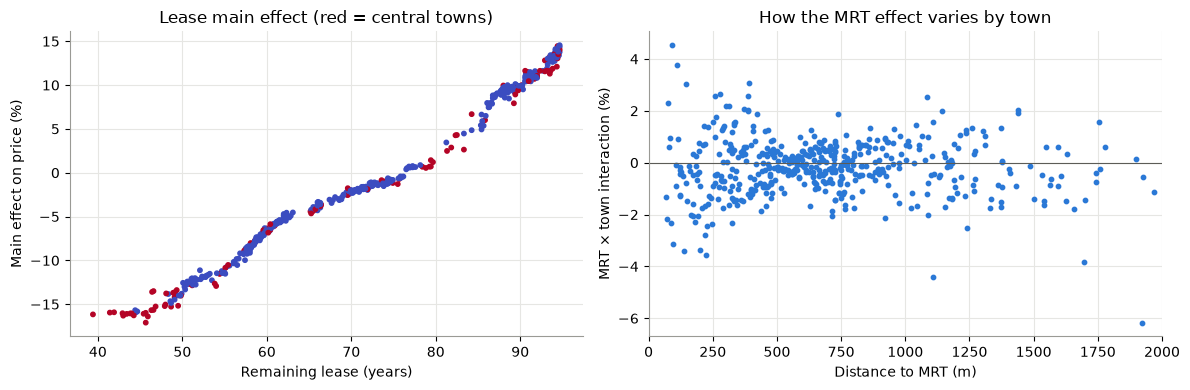

In [8]:
import shap
booster = lgb.Booster(model_file=str(C.PROCESSED / "hedonic_model.txt"))
cats = {c: pd.Categorical(d[c]).categories for c in H.CAT}
recent = d[d["t"] > K.month_index(AS_OF) - 12].sample(500, random_state=4)
Xs = recent[H.FEATURES].copy()
for c in H.CAT: Xs[c] = pd.Categorical(Xs[c], categories=cats[c]).codes.astype(float)   # TreeExplainer needs numeric codes
t1 = time.time(); siv = shap.TreeExplainer(booster).shap_interaction_values(Xs); print(f"interaction values in {time.time() - t1:.0f}s")
mean_abs = np.abs(siv).mean(0); F_ = H.FEATURES
pairs = sorted([(mean_abs[i, j] * 2, F_[i], F_[j]) for i in range(len(F_)) for j in range(i + 1, len(F_))], reverse=True)[:8]
main = sorted([(mean_abs[i, i], F_[i]) for i in range(len(F_))], reverse=True)[:6]
print("Largest main effects (mean |SHAP|, log price):", [(f, round(v, 4)) for v, f in main])
print("Largest interactions (mean |SHAP|, log price):"); [print(f"  {a} × {b}: {v:.4f}") for v, a, b in pairs]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
i, j = F_.index("remaining_lease_yrs"), F_.index("t")
sc = ax[0].scatter(recent["remaining_lease_yrs"], siv[:, i, i] * 100, c=recent["town"].map(lambda t: 1 if t in ("QUEENSTOWN", "BUKIT MERAH", "TOA PAYOH", "KALLANG/WHAMPOA", "CENTRAL AREA", "BISHAN", "BUKIT TIMAH", "MARINE PARADE", "GEYLANG") else 0), cmap="coolwarm", s=10)
ax[0].set(xlabel="Remaining lease (years)", ylabel="Main effect on price (%)", title="Lease main effect (red = central towns)")
k = F_.index("dist_mrt_m"); ft_ = F_.index("town")
ax[1].scatter(recent["dist_mrt_m"], siv[:, k, ft_] * 2 * 100, s=10, color=BLUE); ax[1].axhline(0, color="#5c5c57", lw=0.8)
ax[1].set(xlim=(0, 2000), xlabel="Distance to MRT (m)", ylabel="MRT × town interaction (%)", title="How the MRT effect varies by town")
plt.tight_layout(); plt.show()

**Finding:** Main effects dominate (mean |SHAP| in log price: market timing 0.22, floor area 0.12, town 0.10, flat type 0.08, lease 0.08, MRT 0.03). The largest interactions are each about a fifth of a main effect or less:

- **floor area × town** (0.020) and **floor area × flat type** (0.018): space is worth more per sqm in some towns, and its value depends on flat type
- **lease × town** (0.018): short leases are discounted differently by location
- **market timing × town** (0.014): regions' prices moved at different speeds
- **lease × market timing** (0.013): the lease discount changed over 2017–2026, consistent with buyers pricing lease decay more steeply in recent years

The MRT effect varies by town by about ±2–4%. A linear model would need these interactions specified by hand; the tree model finds them, and SHAP makes them visible.

## 7 · Rolling backtest of profile prices, 2019–2025
At each June the model is refitted on data up to then (1,500 trees), profiles are priced as of that month, and prices are compared with the
median actually paid over the next 12 months (profiles with 5+ sales). Benchmark: the previous 12 months' median.

2019-06 done 22s


2020-06 done 43s


2021-06 done 65s


2022-06 done 88s


2023-06 done 113s


2024-06 done 138s


2025-06 done 164s
         profiles  market drift (median actual/model)  model median |error|  naive median |error|  model |error| net of drift  naive |error| net of drift  model within 10% (net of drift)  rank corr (model)
as_of                                                                                                                                                                                                        
2019-06       795                              1.0058                0.0277                0.0281                      0.0271                      0.0283                           0.9044             0.9849
2020-06       928                              1.0665                0.0677                0.0571                      0.0313                      0.0352                           0.9256             0.9860
2021-06       965                              1.0695                0.0699                0.1136                      0.0231                      0.0378     

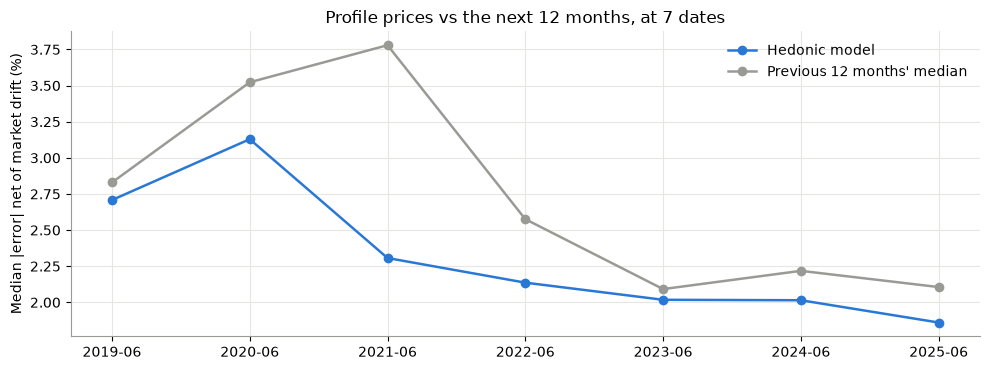

In [9]:
def next12_median(as_of):
    rows = PR.profile_rows(as_of); key = rows.set_index(["address", "flat_type", "storey_band"])["profile_id"]
    t_end = K.month_index(as_of); s = K.sales()
    s = s[s["in_scope"] & (s["t"] > t_end) & (s["t"] <= t_end + 12)].drop(columns="profile_id")
    s = s.assign(storey_band=K.band(s["storey_mid"], C.STOREY_BANDS)).join(key, on=["address", "flat_type", "storey_band"], how="inner")
    return s.groupby("profile_id")["resale_price"].agg(n="size", actual="median").query("n >= 5")
rows = []; t1 = time.time()
for as_of in ["2019-06", "2020-06", "2021-06", "2022-06", "2023-06", "2024-06", "2025-06"]:
    m = H.fit(as_of, rounds=1500); pr, _ = H.price_profiles(m, as_of)
    act = next12_median(as_of); nv = PR.current_profiles(as_of).set_index("profile_id")["median_price_last12"]
    b = act.join(pr.set_index("profile_id")["price"]).join(nv.rename("naive")).dropna()
    rm, rn = b["actual"] / b["price"], b["actual"] / b["naive"]
    rows.append({"as_of": as_of, "profiles": len(b), "market drift (median actual/model)": rm.median(),
                 "model median |error|": (rm - 1).abs().median(), "naive median |error|": (rn - 1).abs().median(),
                 "model |error| net of drift": (rm / rm.median() - 1).abs().median(), "naive |error| net of drift": (rn / rn.median() - 1).abs().median(),
                 "model within 10% (net of drift)": ((rm / rm.median() - 1).abs() <= 0.1).mean(), "rank corr (model)": spearmanr(b["price"], b["actual"]).correlation})
    print(f"{as_of} done {time.time() - t1:.0f}s")
rb_ = pd.DataFrame(rows).set_index("as_of"); print(rb_.round(4).to_string())
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(rb_.index, rb_["model |error| net of drift"] * 100, marker="o", color=BLUE, label="Hedonic model")
ax.plot(rb_.index, rb_["naive |error| net of drift"] * 100, marker="o", color=GREY, label="Previous 12 months' median")
ax.set(ylabel="Median |error| net of market drift (%)", title="Profile prices vs the next 12 months, at 7 dates"); ax.legend()
plt.tight_layout(); plt.show()

**Finding:** Across 7 June as-of dates (2019–2025, 795–1,036 profiles each), the hedonic profile prices beat the previous 12 months' median at every date, once market drift is removed:

- **Error net of drift:** 1.9–3.1% for the model against 2.1–3.8% for the median.
- **Within 10%:** 90–98% of profiles.
- **Rank correlation with actual prices:** 0.985–0.993.

Before removing drift, the model is better at 5 of 7 dates. The exceptions are 2020, when prices jumped 6.7% in the following year, and 2019 (a tie). The model is a "today" price; the market's next-year move (0.6–7.0% across these dates) is what the forecasting layer adds.

## 8 · Our index vs HDB's Resale Price Index
HDB publishes a quarterly Resale Price Index (1Q2009 = 100; [HDB RPI table](https://www.hdb.gov.sg/-/media/managing-my-home/selling-a-flat/process-for-selling-a-flat/resale-flat-planning/resale-statistics/RPI-Table.pdf), 3Q2026 is a flash estimate). Our hedonic index (step 5, all regions) is combined across flat types
with 2017 sales weights, averaged by quarter, and both are rebased to 1Q2017 = 100.

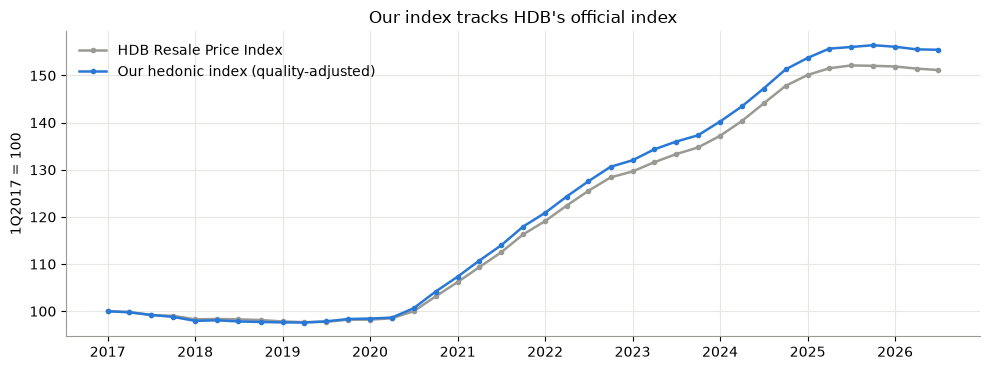

Quarters compared: 39 (2017Q1–2026Q3) · level correlation 1.000 · quarterly-change correlation 0.993
Cumulative change to 2026Q3: HDB RPI +51.2% · ours +55.5%
Mean absolute gap in levels: 1.8 index points


In [10]:
rpi = pd.Series([133.9, 133.7, 132.8, 132.6, 131.6, 131.7, 131.6, 131.4, 131.0, 130.8, 130.9, 131.5, 131.5, 131.9, 133.9, 138.1,
                 142.2, 146.4, 150.6, 155.7, 159.5, 163.9, 168.1, 171.9, 173.6, 176.2, 178.5, 180.4, 183.7, 187.9, 192.9, 197.9,
                 201.0, 202.9, 203.7, 203.6, 203.4, 202.8, 202.4], index=pd.period_range("2017Q1", "2026Q3", freq="Q"), name="HDB RPI")
ix = pd.read_csv(C.OUTPUTS / "price_index_v1.csv"); ix = ix[ix["region"] == "ALL"]
w = K.sales().query("in_scope and month < '2018-01'")["flat_type"].value_counts(normalize=True)
ix = ix.assign(w=ix["flat_type"].map(w)).dropna(subset=["w"])
ours = ix.groupby("month").apply(lambda g: np.exp(np.average(np.log(g["index"]), weights=g["w"])))
ours.index = pd.PeriodIndex(ours.index, freq="M"); ours_q = ours.groupby(ours.index.asfreq("Q")).mean().rename("Our hedonic index")
both = pd.concat([rpi / rpi.iloc[0] * 100, ours_q / ours_q.iloc[0] * 100], axis=1).dropna()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(both.index.to_timestamp(), both["HDB RPI"], color=GREY, marker="o", ms=3, label="HDB Resale Price Index")
ax.plot(both.index.to_timestamp(), both["Our hedonic index"], color=BLUE, marker="o", ms=3, label="Our hedonic index (quality-adjusted)")
ax.set(ylabel="1Q2017 = 100", title="Our index tracks HDB's official index"); ax.legend(); plt.tight_layout(); plt.show()
g = both.pct_change().dropna()
print(f"Quarters compared: {len(both)} ({both.index[0]}–{both.index[-1]}) · level correlation {both.corr().iloc[0, 1]:.3f} · quarterly-change correlation {g.corr().iloc[0, 1]:.3f}")
print(f"Cumulative change to {both.index[-1]}: HDB RPI {both['HDB RPI'].iloc[-1] - 100:+.1f}% · ours {both['Our hedonic index'].iloc[-1] - 100:+.1f}%")
print(f"Mean absolute gap in levels: {(both['HDB RPI'] - both['Our hedonic index']).abs().mean():.1f} index points")

**Finding:** Our quality-adjusted index tracks HDB's official Resale Price Index closely over 39 quarters (2017Q1–2026Q3):

- **Correlation:** 1.000 in levels and 0.993 in quarter-on-quarter changes.
- **Mean gap:** 1.8 index points.
- **Cumulative rise:** ours +55.5% against HDB's +51.2%.

The small difference is consistent with a different weighting and quality adjustment (fixed 2017 flat-type weights and a block-level hedonic, against HDB's own method). This external check validates the index that Forecasting builds on.

## 9 · Summary

**Finding:** The hedonic model passes every check of a professional valuation model:

| Check | Result |
|---|---|
| Unseen blocks | MAPE 3.9% vs 6.6% linear |
| Later period | 4.4% vs 6.9%; drift handled by Forecasting |
| Unseen towns | 8.0% without the town label; usable for new towns |
| Hyperparameters | Production within 0.04 pp of the best of 9 |
| Feature groups | Amenities +0.32 pp, location below town +0.97 pp; lat/lon and neighbourhood premium add nothing |
| Monotone constraints | Cost 0.09 pp; prevent wrong-signed prices for up to 28% of flats |
| Residual bias | Within ±0.3% by year, flat type and price decile; residual Moran's I 0.07 |
| Prediction intervals | Conformal 80% ±6.4% → 81% coverage; 90% ±8.9% → 91% |
| Interactions | Size × town, lease × town, lease × time; MRT premium varies ±2–4% by town |
| Rolling backtest, 7 dates | Beats the 12-month median at every date net of drift |
| Official index | Correlation 0.993 with HDB RPI changes |